# Fundamentos de la Computación Cuántica - Tercera Entrega

A lo largo de la _notebook_, se resuelve el ejercicio final solicitado por la cátedra de la materia optativa Fundamentos de la Computación Cuántica como entrega final de la cursada. La consigna de este corresponde al ejercicio 4 del trabajo práctico N.° 4 y se enuncia a continuación:

_Implementar y analizar en Qiskit un multiplicador entre dos números binarios codificados en 3 qubits (mediante estados básicos), basado en dominio de Fourier. Debe implementarse, para ello, la transformada cuántica de Fourier inversa completa._

En esta _notebook_ se presentan las cuestiones relacionadas a la implementación del ejercicio. Para visualizar la lógica y el pensamiento detrás de estas, revise el informe adjunto con la entrega.

## Imports

Previo a la resolución del ejercicio, se realiza la importación de las librerías utilizadas:

In [3]:
import math
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Para la visualización de los resultados en tablas:
import os
import matplotlib.pyplot as plt # Utilizada para generación de tablas.

## Transformada Cuántica de Fourier Inversa (IQFT)

Como primer paso de la resolución del ejercicio, se realiza la implementación de la transformada cuántica de Fourier inversa. Para ello, se utiliza como base el siguiente ejemplo proporcionado por la cátedra:

![IQFT4.png](images/iqft4.png)

A continuación, se presenta la implementación de la IQFT, generalizada a N qubits:

In [4]:
def IQFT(number_of_qubits):
    
    quantum_circuit = QuantumCircuit(number_of_qubits, name="IQFT")
    
    accesible_qubits = number_of_qubits - 1
    
    # Swaps. Estos pueden ahorrarse si se invierte el orden de los qubits resultados.
    for i in range(int(number_of_qubits/2)):
        quantum_circuit.swap(i, accesible_qubits - i)
        
    # Barrera colocada con motivos de separación estética.
    quantum_circuit.barrier()
        
    # Aplicación de rotaciones a los qubits.
    # Por cada qubit, se aplica una rotación extra.
    # Al primer qubit, solo se le aplica Hadamard.
    # Al segundo, una rotación de pi/2 y Hadamard.
    # Al tercero, una rotación de pi/4, una rotación de pi/2 y Hadamard.
    # Y así sucesivamente, considerando en todo momento potencias de 2.
    for i in range(number_of_qubits):
        
        # Aplicación de rotaciones.
        for j in range(i, 0, -1):
            quantum_circuit.cp(-math.pi/(2 ** j), i - j, i)
        
        # Luego de las rotaciones, se aplica un Hadamard.
        quantum_circuit.h(i)
        
        # Se aplica una barrera para evitar el autoordenamiento de Qiskit.
        quantum_circuit.barrier()
        
    return quantum_circuit

Para 4 qubits, como el ejemplo presentado, el circuito resultante es el siguiente:

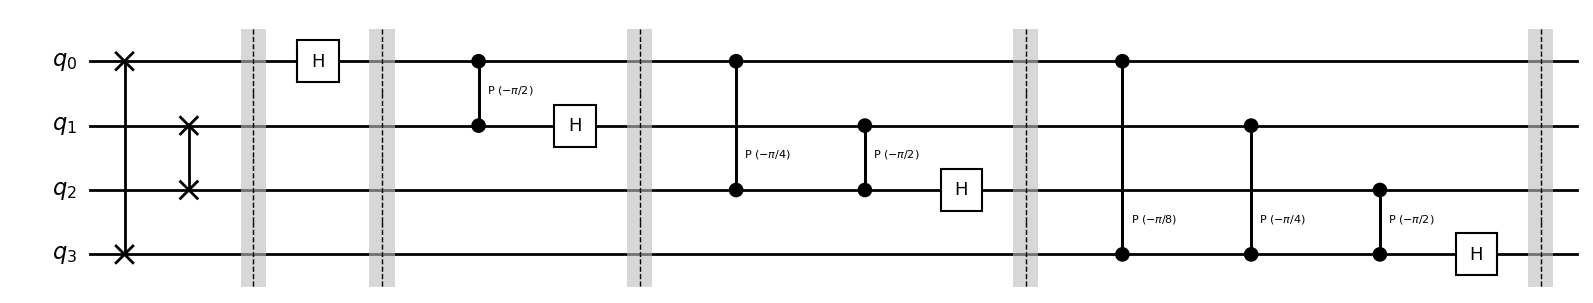

In [5]:
qc = IQFT(4)
qc.draw(output='mpl', style='bw')

En el caso particular del multiplicador solicitado, el máximo número representable por un operando de 3 qubits es 7 (111). Por consiguiente, el máximo valor obtenible de la multiplicación de dos operandos de tres qubits es 7 x 7 = 49. El número 49 puede descomponerse en potencias de dos como:

_1\*2^5 (32) + 1\*2^4 (16) + 0\*2^3 + 0\*2^2 + 0\*2^1 + 1\*2^0 (1)_

Lo que genera el siguiente número binario: 110001.

Por consiguiente, la transformada cuántica de Fourier inversa a considerar es la correspondiente a seis qubits, cuyo circuito es el siguiente:


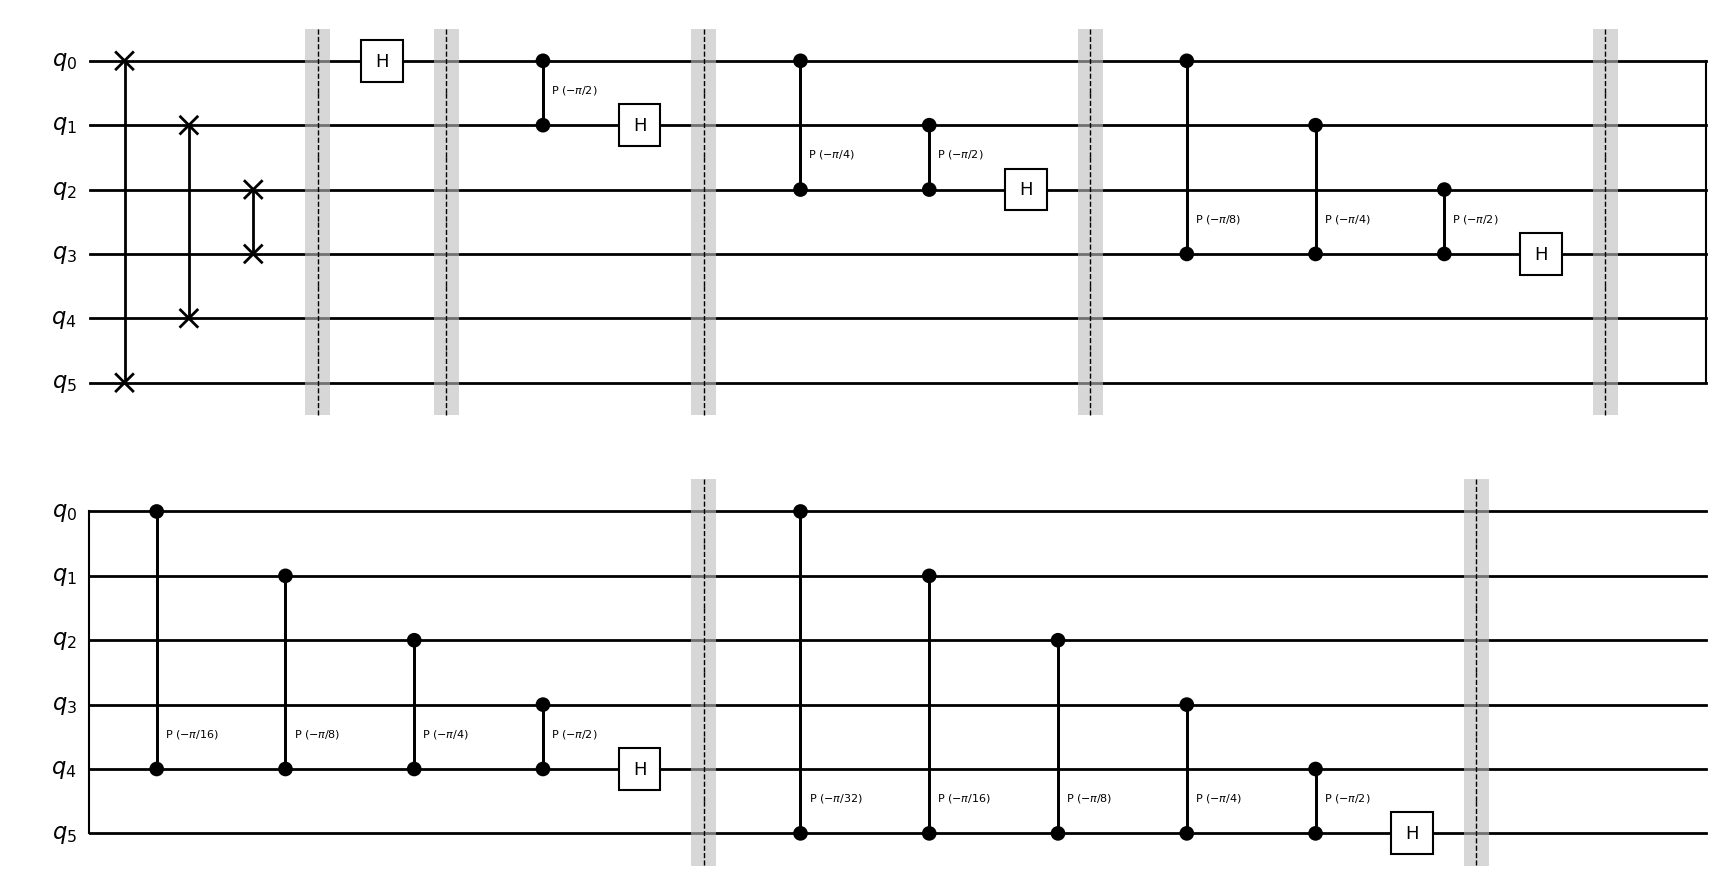

In [6]:
qc = IQFT(6)
qc.draw(output='mpl', style='bw')

## Multiplicador entre dos Números Binarios codificados en 3 qubits

Con la IQFT ya implementada, se prosigue con la implementación del multiplicador.

### Sumador

Una parte fundamental del multiplicador es el sumador, puesto a que una multiplicación no es más que una sucesión de sumas. Con esto en cuenta, se realiza su implementación, basada en dominio de Fourier:

In [7]:
def plusN(n, result_qubits):
    
    # Creación del circuito.
    qc = QuantumCircuit(result_qubits, name=f"+{n}")
    
    for i in range(result_qubits):
        
        # Fórmula: Angulo Base * Valor.
        angulo = (math.pi / (2 ** i)) * n
        
        # Aplicación de la rotación.
        qc.p(angulo, result_qubits - 1 - i) 
        
    return qc

Considerando seis qubits resultado, el circuito correspondiente al sumador +1 es el siguiente:

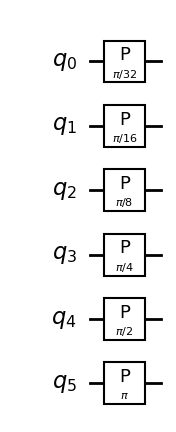

In [8]:
plusN(1, 6).draw(output='mpl', style='bw')

Si se desea sumar _N_, como se detalla en el informe, basta con multiplicar las rotaciones por dicho valor. Por ejemplo, si se desea sumar 4, el circuito resultante es el siguiente:

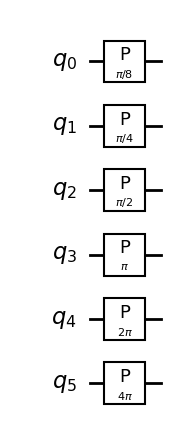

In [9]:
plusN(4, 6).draw(output='mpl', style='bw')

Como puede observarse, este circuito es similar al circuito presentado anteriormente. La diferencia se encuentra en que las rotaciones están multiplicadas por cuatro.

### Multiplicador

Con el sumador implementado, se prosigue con la implementación del multiplicador:

In [10]:
def multiplier(qubits_in_first_operand, qubits_in_second_operand=None):
    
    # De no especificarse la cantidad de qubits en el segundo operando,
    # se asume que esta es igual a la cantidad de qubits en el primer operando.
    if qubits_in_second_operand == None:
        qubits_in_second_operand = qubits_in_first_operand
    
    # En el peor de los casos, la multiplicación de un operando de m bits y un operando
    # de n bits tiene como resultado a un número de m + n bits.
    result_qubits = qubits_in_first_operand + qubits_in_second_operand
    
    # Qubits totales dirigidos a operandos.
    operands_qubits = qubits_in_first_operand + qubits_in_second_operand
    
    # Qubits totales en el circuito.
    total_qubits = operands_qubits + result_qubits
    
    # Creación del circuito.
    quantum_circuit = QuantumCircuit(total_qubits, name=f"MUL")
    
    # Aplicación de Hadamard a los qubits resultado.
    for i in range(operands_qubits, total_qubits, 1):
        quantum_circuit.h(i)
        
    # Lista de compuertas a descomponer.
    # Qiskit automáticamente crea cajas negras que dificultan el
    # entendimiento del circuito. Esto se plantea con el objetivo de
    # luego deshacer dichas simplificaciones y observar el circuito
    # de forma más clara.
    gates_to_descompose = []
    
    for i in range(qubits_in_first_operand):
        
        # Valor del i-ésimo qubit del primer operando.
        first_operand_value = 2 ** i
        
        for j in range(qubits_in_second_operand):
            
            # Valor del j-ésimo qubit del segundo operando.
            second_operand_value = 2 ** j
            
            # Resultado de la multiplicación de los operandos.
            value_to_sum = first_operand_value * second_operand_value
            
            # Creación de la compuerta de suma.
            sum_gate = plusN(value_to_sum, result_qubits)
            
            # La columna es controlada por dos qubits: Xi e Yj.
            controlled_gate = sum_gate.control(2)
            
            # Se añade la compuerta controlada a la lista de compuertas a descomponer.
            if controlled_gate.name not in gates_to_descompose:
                gates_to_descompose.append(controlled_gate.name)
        
            # Se definen los "cables": [ControlX, ControlY, Objetivo1, Objetivo2, Objetivo3...].
            qubit_control = [i, j + qubits_in_first_operand] #Xi y Yj, respectivamente.
            qubits_objetivo = list(range(operands_qubits, total_qubits)) # Qubits del acumulador.
            
            # Cableado.
            wiring = qubit_control + qubits_objetivo
            
            # Agregado de la compuerta al circuito.
            quantum_circuit.append(controlled_gate, wiring)
    
    # Se descomponen las compuertas con controles de forma que Qiskit no genere
    # automáticamente una caja negra y pueda verse claramente quién activa cada compuerta.
    quantum_circuit = quantum_circuit.decompose(gates_to_decompose=gates_to_descompose)
        
    # Se añade la transformada cuántica de Fourier inversa para decodificar el resultado.
    quantum_circuit.append(IQFT(result_qubits), list(range(operands_qubits, total_qubits)))
    
    # Se retorna el circuito y la cantidad de qubits en el resultado.
    return quantum_circuit, result_qubits

Para operandos de 3 qubits, como solicita el ejercicio, el circuito resultante es el siguiente:

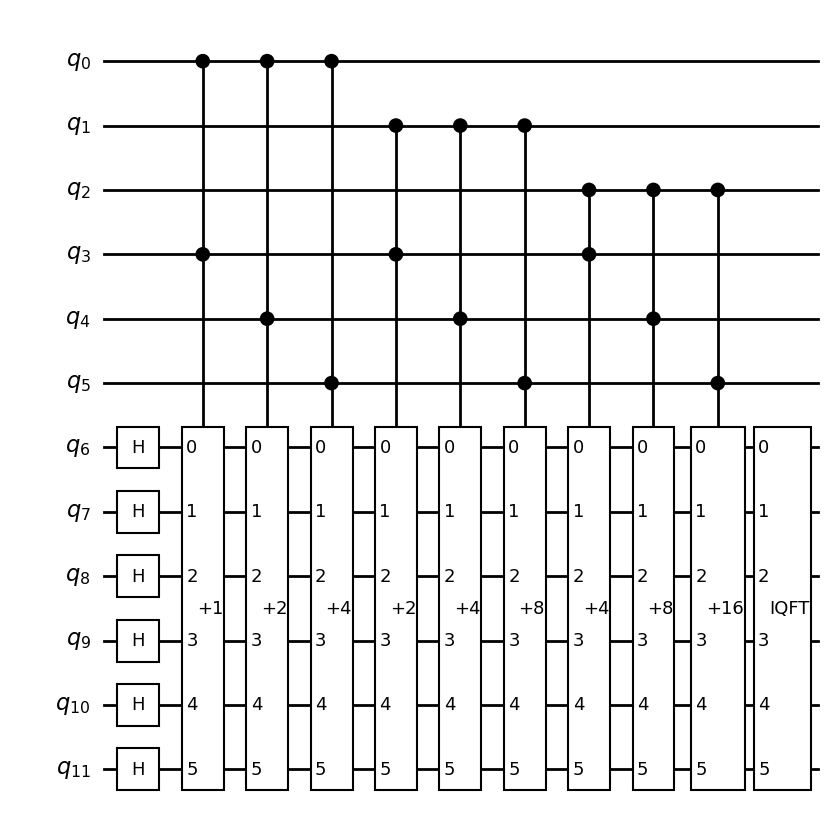

In [11]:
qubits_in_operands = 3
qc, result_qubits = multiplier(qubits_in_operands)
qc.draw(output='mpl', style='bw')

A continuación, se colocan en superposición las entradas del circuito y se añaden medidores para corroborar su funcionamiento:

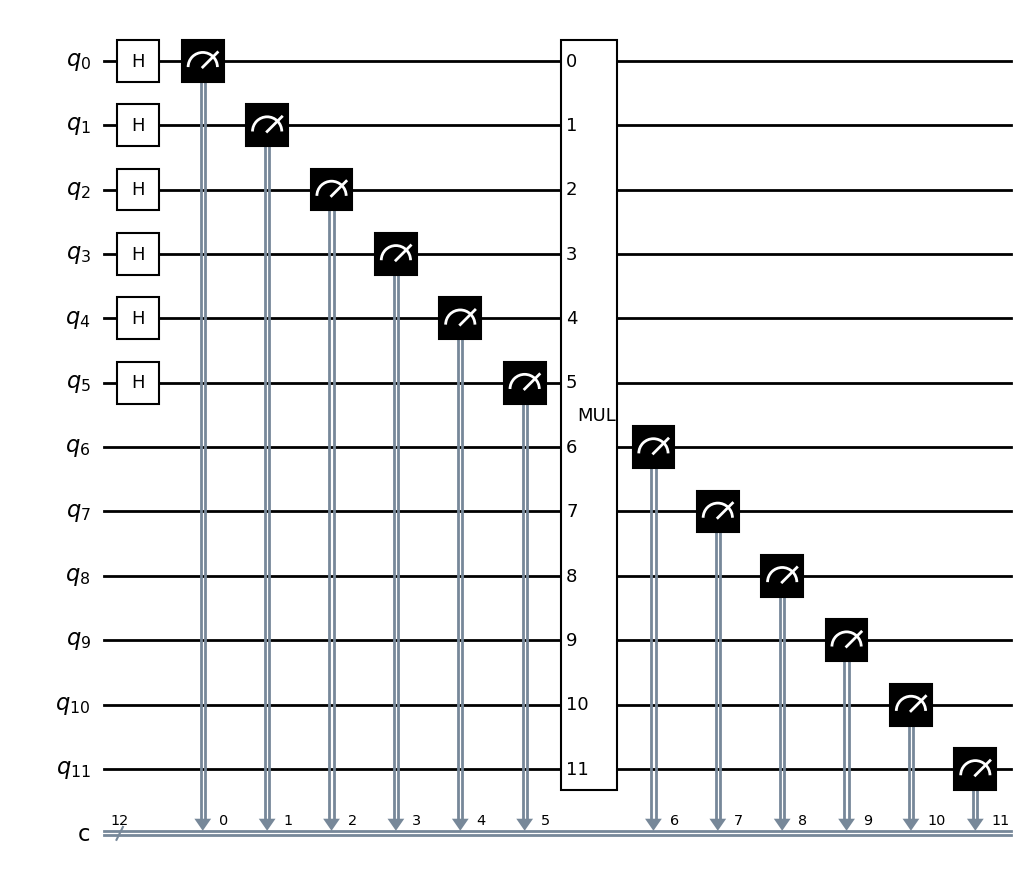

In [12]:
def add_measurements(input_qubits, result_qubits, quantum_circuit):
    
    total_qubits = input_qubits + result_qubits
    
    measured_quantum_circuit = QuantumCircuit(total_qubits, total_qubits)

    # Superposición de los operandos.
    measured_quantum_circuit.h(list(range(input_qubits)))

    # Medición de los valores de los operandos.
    measured_quantum_circuit.measure(list(range(input_qubits)), list(range(input_qubits)))

    # Se añade el multiplicador.
    measured_quantum_circuit.append(quantum_circuit, list(range(total_qubits)))

    # Se añaden las mediciones correspondientes a los qubits resultado.
    for i in range(input_qubits, total_qubits, 1):
        measured_quantum_circuit.measure(i, i)
        
    # Se retorna el circuito con las mediciones.
    return measured_quantum_circuit

measured_quantum_circuit = add_measurements(qubits_in_operands * 2, result_qubits, qc)
measured_quantum_circuit.draw(output='mpl', style='bw')

Con las mediciones añadidas, se ejecuta una simulación de 10240 shots:

In [13]:
def simulate(measured_quantum_circuit):
    simulator = AerSimulator()
    transpiled = transpile(measured_quantum_circuit, simulator)
    job = simulator.run(transpiled, shots=10240)
    results = job.result()
    counts = results.get_counts(transpiled)

    histogram = plot_histogram(counts, title="Resultados", color="#1D1A1A")
    histogram.axes[0].set_ylabel("Frecuencia")

    return histogram, counts
    
_, counts = simulate(measured_quantum_circuit)

A continuación, se generan las tablas correspondientes al reporte de los resultados;

Guardado en: outputs/validacion_mul_parte_1.png


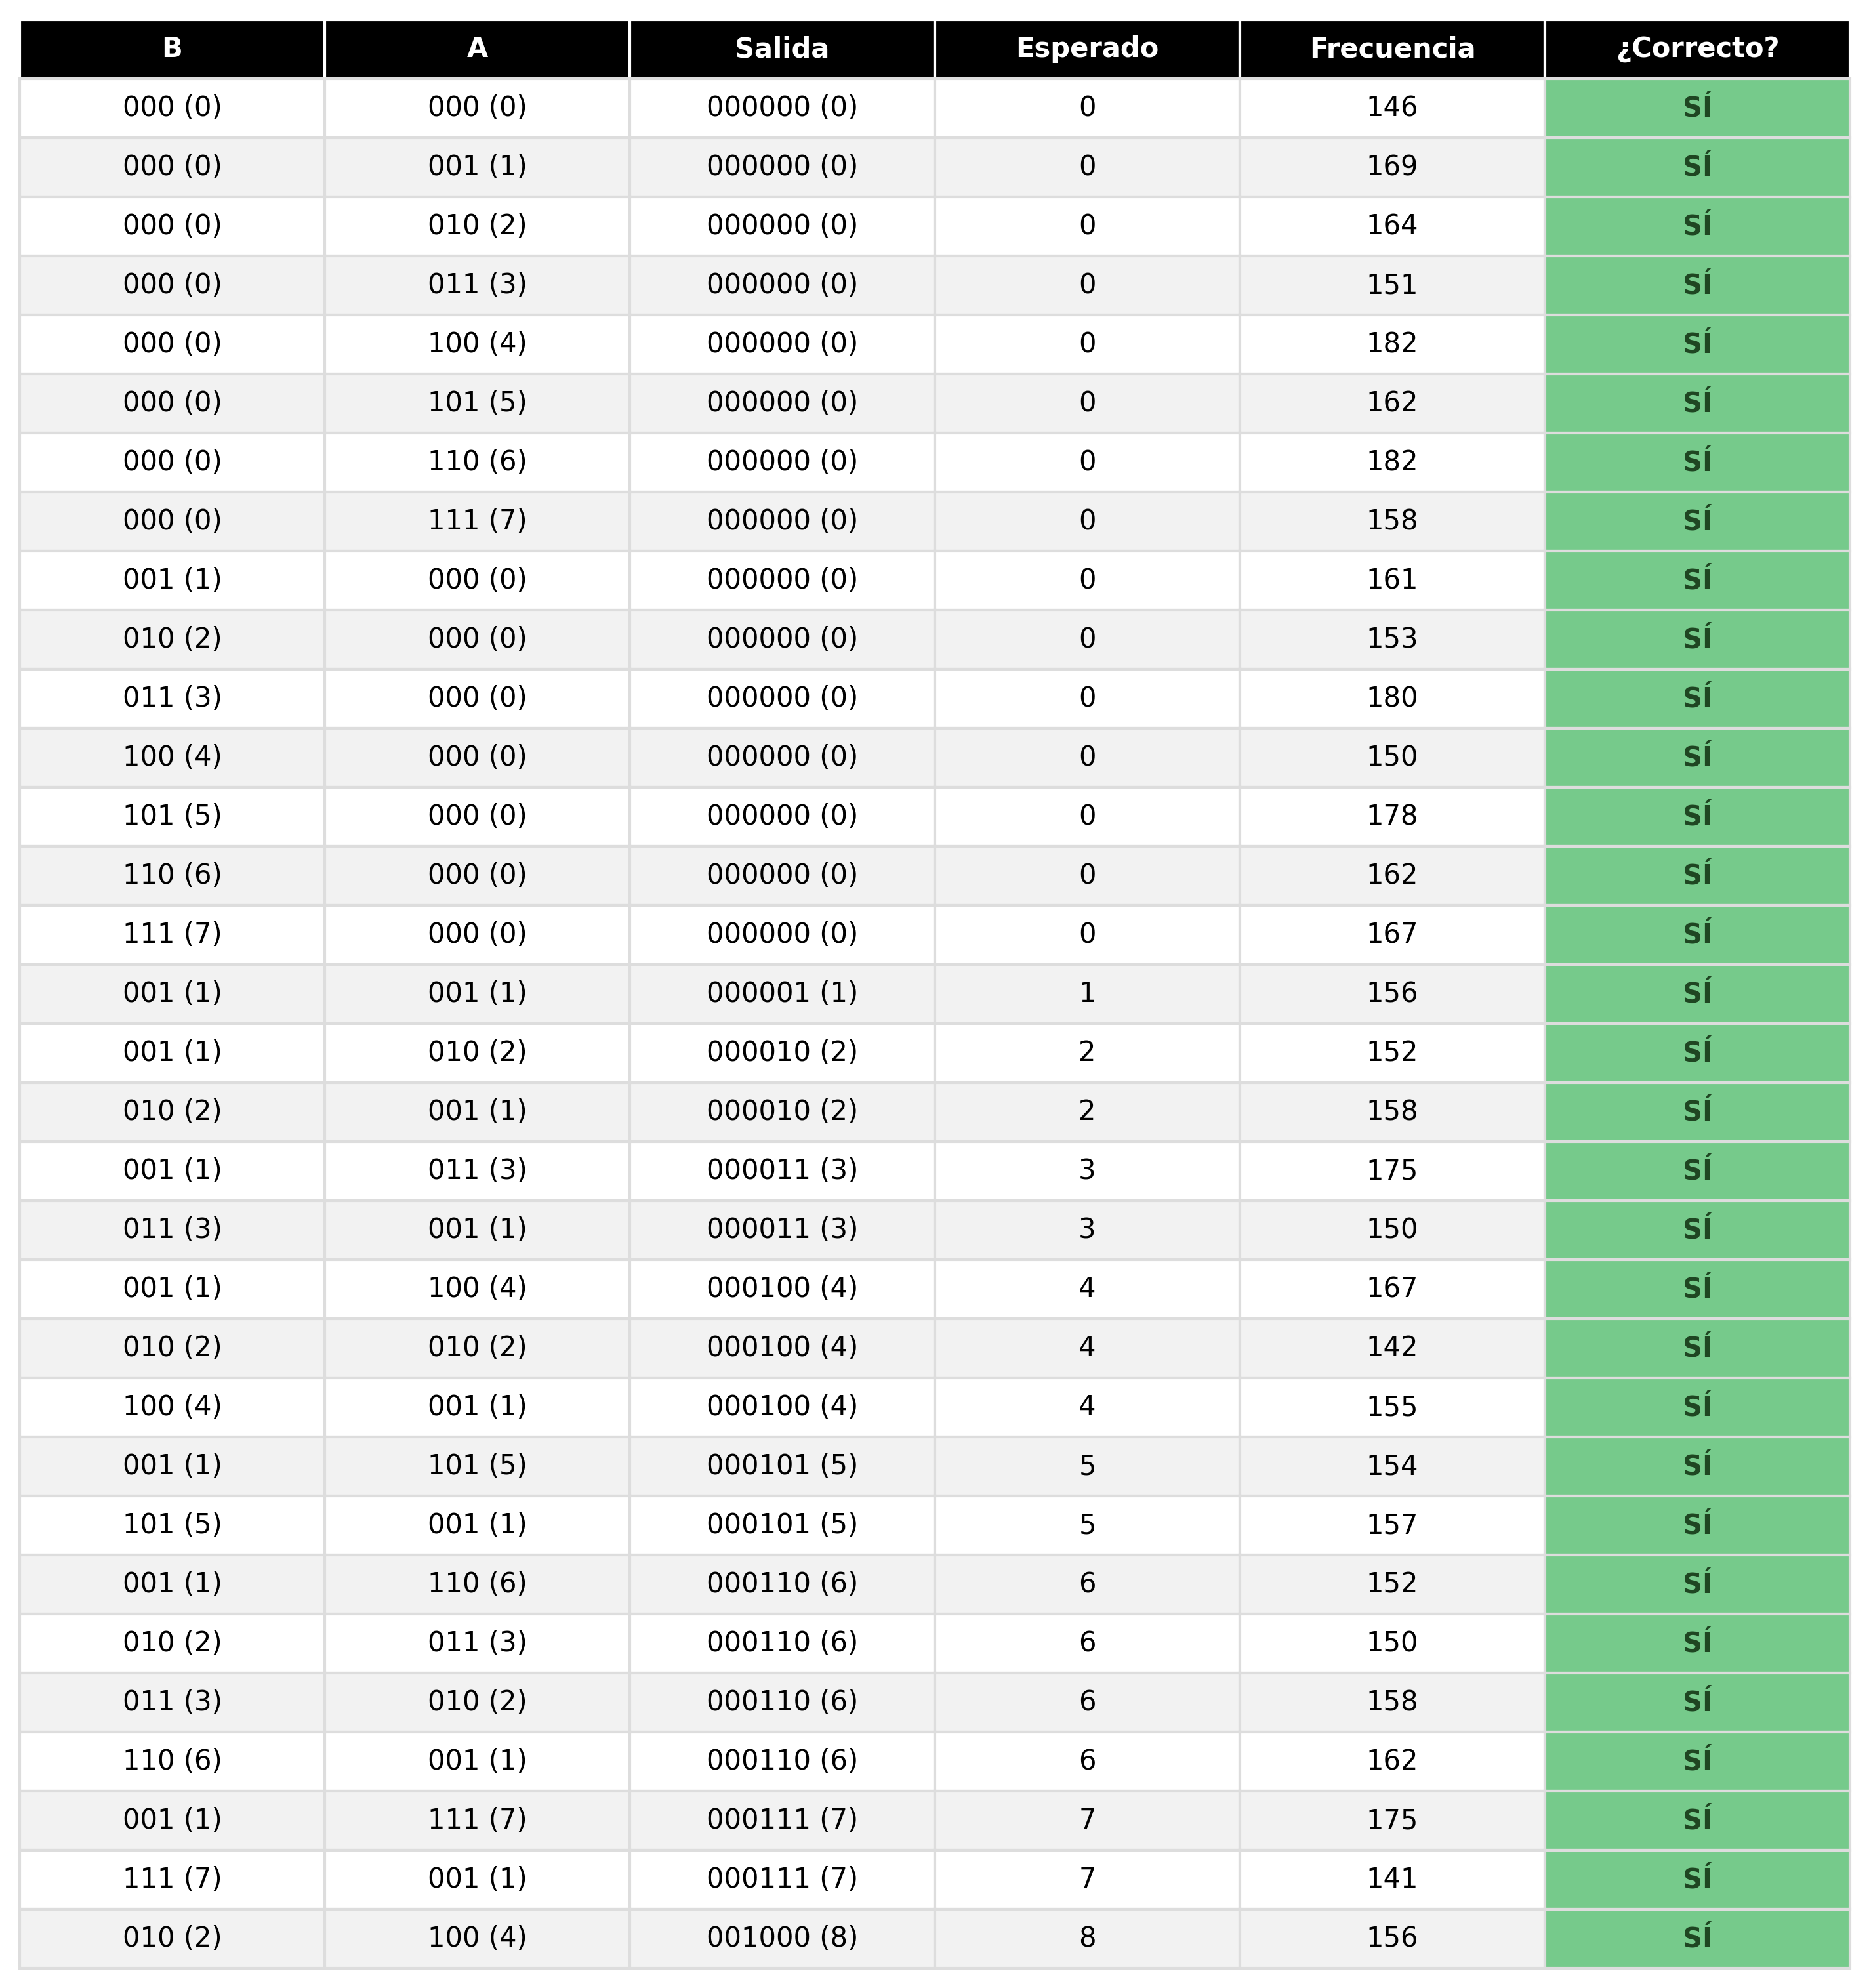

Guardado en: outputs/validacion_mul_parte_2.png


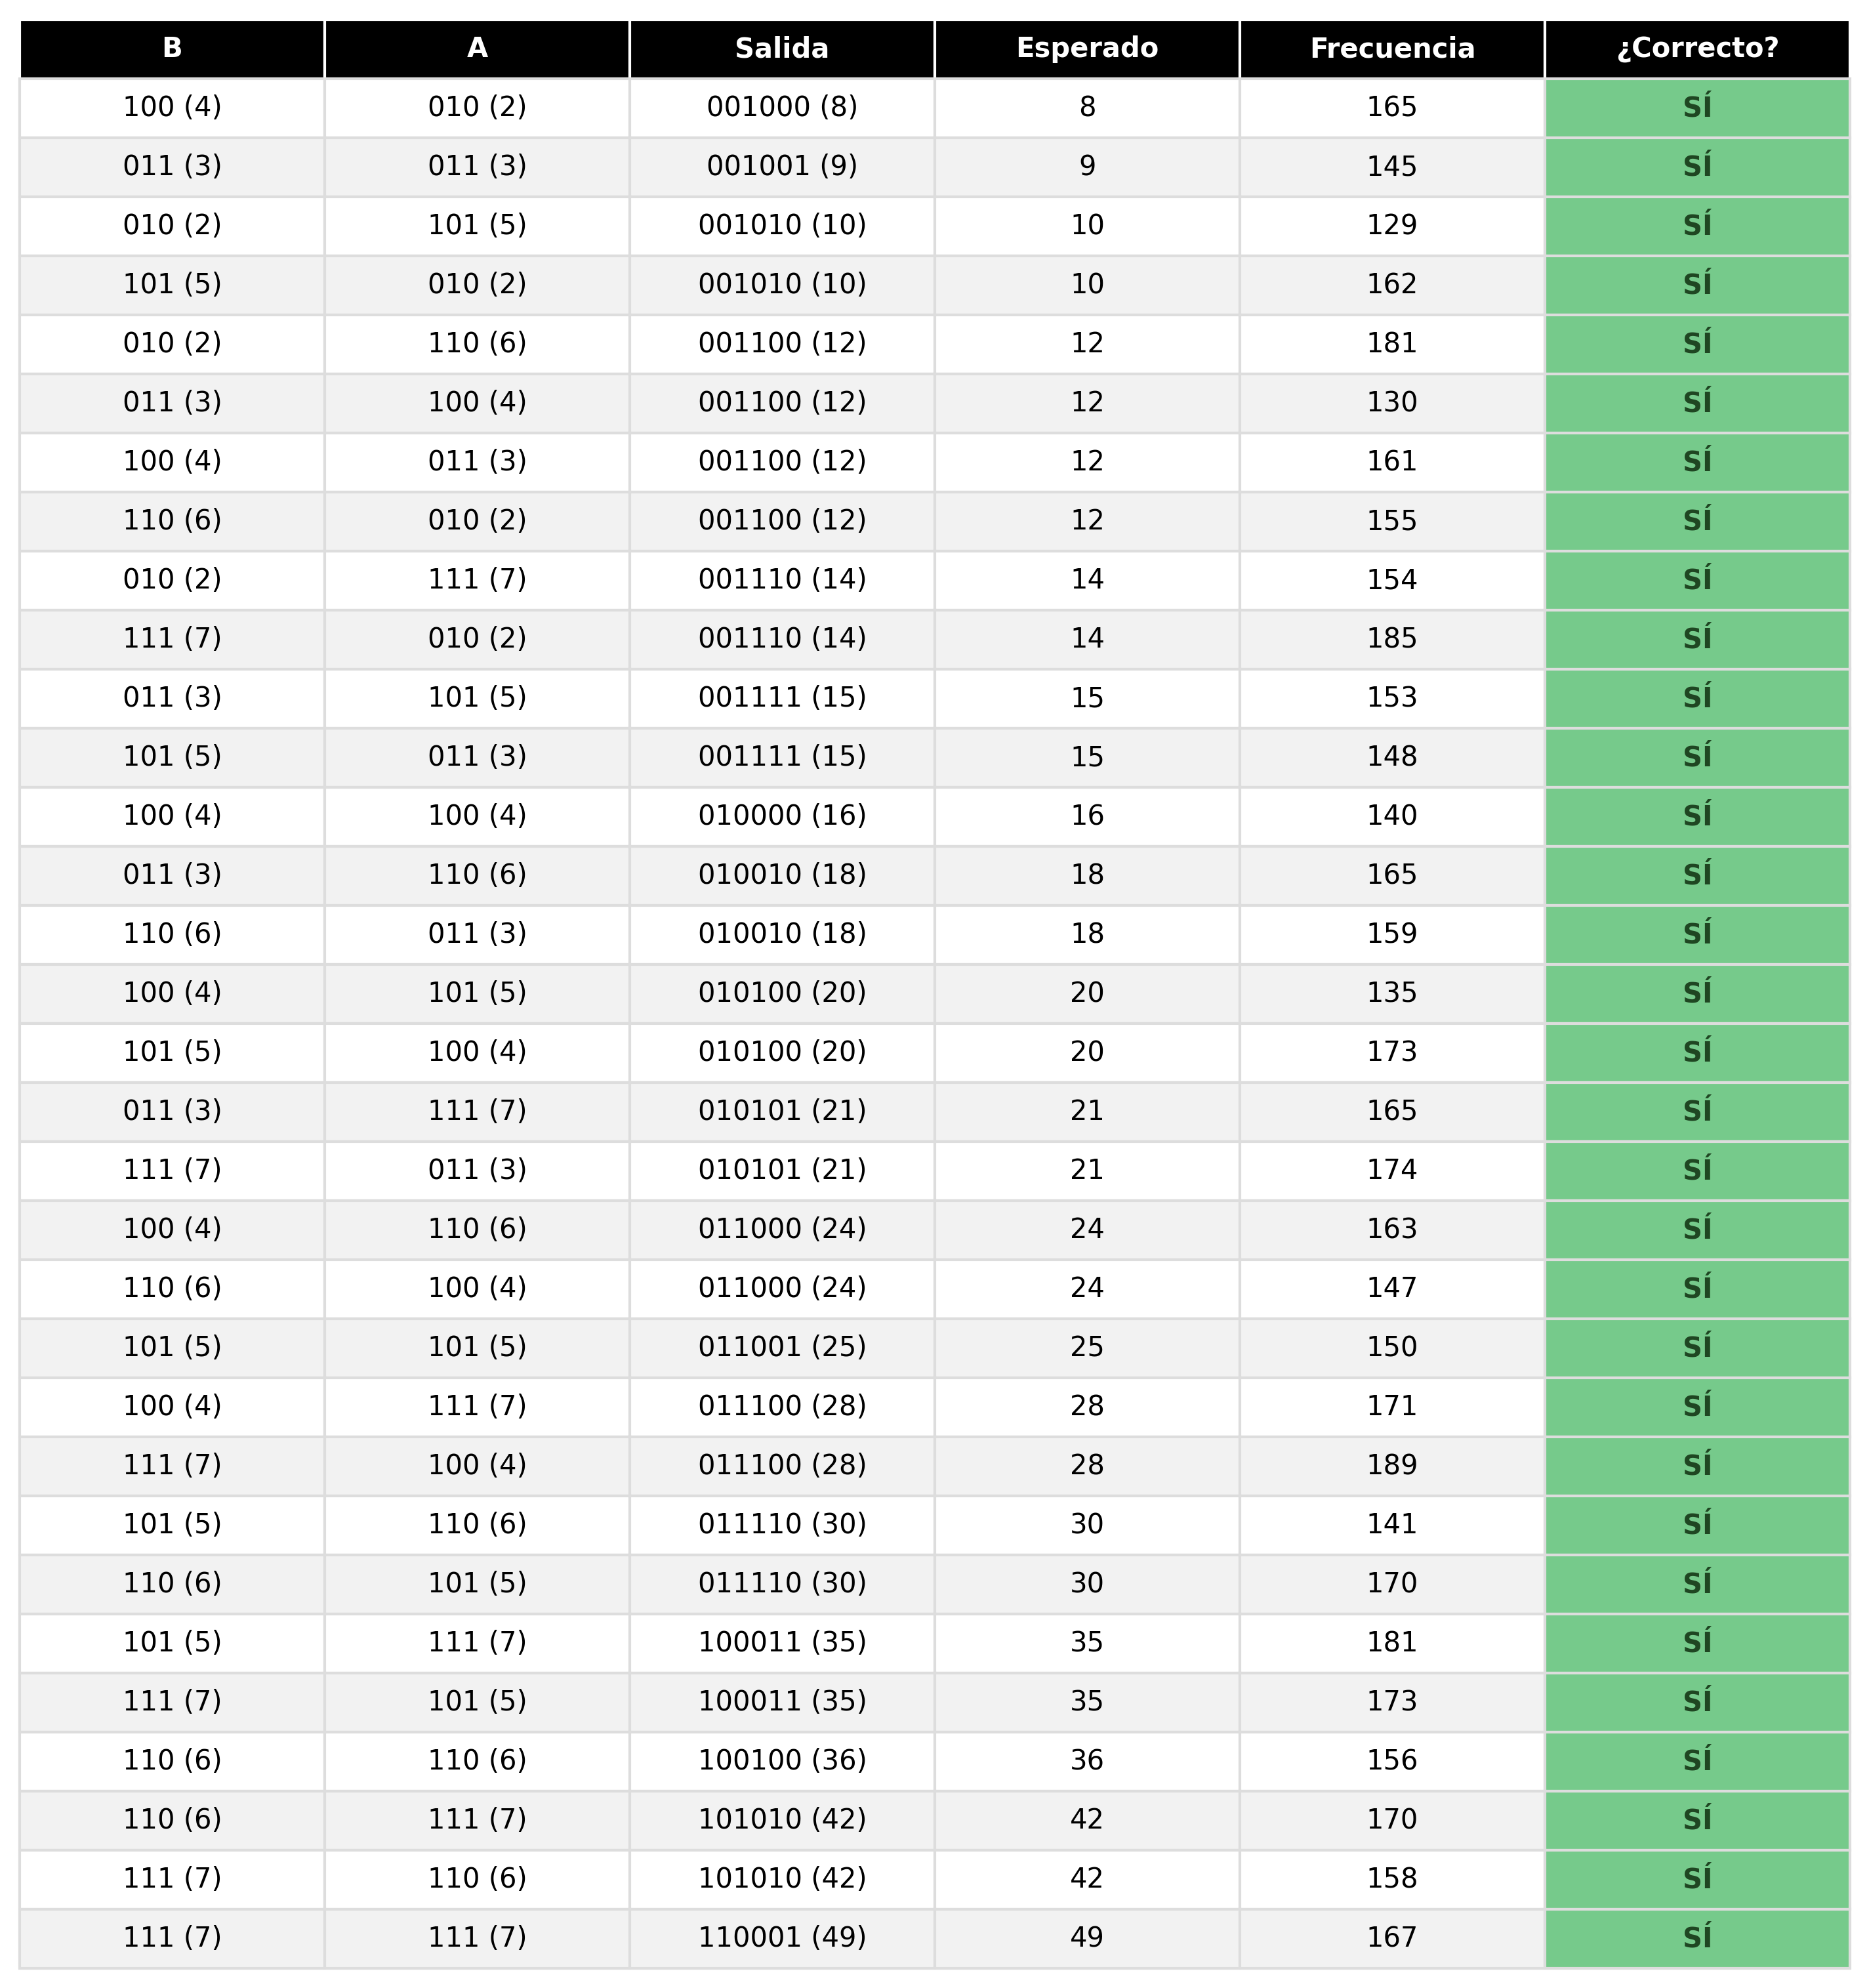

In [14]:
def save_report_table(counts, n_qubits_a, n_qubits_b, n_bits_resultado, filename_base="tabla_mul", max_rows=32):
    """
    Genera múltiples imágenes PNG de alta resolución en las que se presenta la tabla de resultados.
    """
    
    # Preparación de los datos.
    data = []
    column_labels = ["B", "A", "Salida", "Esperado", "Frecuencia", "¿Correcto?"]
    
    # Por cada combinación...
    for bitstring, count in sorted(counts.items()):
        clean_bits = bitstring.replace(" ", "")
        
        # Se obtienen los caracteres correspondientes a los operandos y al resultado.
        chars_a = clean_bits[-n_qubits_a:]
        chars_b = clean_bits[-(n_qubits_a + n_qubits_b) : -n_qubits_a]
        chars_out = clean_bits[-(n_qubits_a + n_qubits_b + n_bits_resultado) : -(n_qubits_a + n_qubits_b)]
        
        # Se calcula el valor decimal de los operandos, el valor esperado y el valor decimal del resultado.
        val_a = int(chars_a, 2)
        val_b = int(chars_b, 2)
        val_real = int(chars_out, 2)
        val_esperado = val_a * val_b
        
        # Se verifica que el resultado real coincida con el esperado.
        es_correcto = val_esperado == val_real
        status_text = "SÍ" if es_correcto else "NO"
        
        # Se añade la fila a la tabla.
        row = [
            f"{chars_b} ({val_b})",
            f"{chars_a} ({val_a})",
            f"{chars_out} ({val_real})",
            val_esperado,
            count,
            status_text
        ]
        data.append(row)

    # Lógica de división (Chunking).
    # Necesario para dividir luego la tabla
    # en varias tablas más chicas.
    total_rows = len(data)
    
    # Se calculan cuántas partes se necesitan.
    num_parts = math.ceil(total_rows / max_rows)

    for i in range(num_parts):
        
        # Se definen el inicio y fin del corte.
        start = i * max_rows
        end = start + max_rows
        
        # Se cortan los datos.
        subset_data = data[start:end]
        
        # Generación de la figura para la parte.
        rows_in_subset = len(subset_data)
        fig_height = max(2, rows_in_subset * 0.1) + 1 # +1 para el header.
        
        _, ax = plt.subplots(figsize=(10, fig_height))
        ax.axis('tight')
        ax.axis('off')
        
        # Creación de la tabla.
        table = ax.table(cellText=subset_data, colLabels=column_labels, cellLoc='center', loc='center')
        
        # Estilizado.
        table.auto_set_font_size(False)
        table.set_fontsize(10)
        table.scale(1.2, 1.8) # Un poco más de alto para que respire

        # Coloreado.
        for (r, c), cell in table.get_celld().items():
            if r == 0: # Header.
                cell.set_text_props(weight='bold', color='white')
                cell.set_facecolor("#000000")
                cell.set_edgecolor('white')
            else: # Datos.
                cell.set_edgecolor('#dddddd')
                
                if c == 5: 
                    # Si bien `subset_data` empieza en 0, la tabla tiene header, por lo que se empieza en r-1.
                    text_val = subset_data[r-1][5]
                    
                    if text_val == "SÍ":
                        cell.set_facecolor("#76CA8B")
                        cell.set_text_props(color="#1F4622", weight='bold')
                    else:
                        cell.set_facecolor('#f8d7da')
                        cell.set_text_props(color='#842029', weight='bold')
                else:
                    if r % 2 == 0:
                        cell.set_facecolor('#f2f2f2')
                    else:
                        cell.set_facecolor('white')
                        
        output_directory = "outputs"
                        
        # Se crea el directorio si no existe. 
        # "exist_ok=True" evita el error si ya existe.
        os.makedirs(output_directory, exist_ok=True)

        # Nombre del archivo, especificando la parte.
        current_filename = f"{output_directory}/{filename_base}_parte_{i+1}.png"
        
        # Título.
        # plt.title(f"Tabla de Verdad - Parte {i+1} de {num_parts}", pad=10, fontsize=12, color="#555555")
        
        # Guardado de la tabla en imágenes.
        plt.savefig(current_filename, bbox_inches='tight', dpi=300)
        plt.close()
        
        print(f"Guardado en: {current_filename}")
        
        # Se muestra en la notebooks el resultado.
        from IPython.display import display, Image
        display(Image(current_filename))

save_report_table(counts, 3, 3, 6, filename_base="validacion_mul", max_rows=32)

Como puede observarse, el funcionamiento del circuito es el esperado.